# Predicción del Top 10 en Fórmula 1 con clasificación y optimización bayesiana

| | |
|:--|:--|
| **Nombres** | Alexa Bojorquez Valdivia - David Farias Rivera |
| **Expedientes** | 745497 - 754381 |
| **Periodo de los datos** | 2020–2024 |

## 1. Objetivos

### Objetivo general
Comparar modelos de clasificación para predecir si un piloto termina entre los diez primeros de una carrera de Fórmula 1 a partir de información disponible antes de la carrera.

### Objetivos específicos
1. Revisar y unir los resultados de los pilotos con las características de los circuitos, identificando faltantes y duplicados.
2. Construir las variables previas a la carrera (posición de salida y rendimiento de la escudería en la temporada) y transformarlas mediante un pipeline.
3. Ajustar regresión logística regularizada, SVC con kernel RBF y una red MLP, optimizando sus hiperparámetros mediante procesos gaussianos.
4. Comparar los modelos con la media y desviación del ROC-AUC en validación cruzada y contra una referencia que solo usa la posición de salida.
5. Evaluar los modelos en la temporada 2024 e identificar qué variables se asocian más con terminar en el Top 10.

### Pregunta de investigación
¿Qué modelo distingue mejor entre terminar dentro y fuera del Top 10 usando información previa a la carrera, y cuánto mejora frente a usar solo la posición de salida?

## 2. Marco teórico

### Regresión logística
Es un modelo para una respuesta categórica (James et al., 2023). En este trabajo $y=1$ indica Top 10 y $y=0$ indica fuera del Top 10. La probabilidad se calcula con:

$$p(y=1\mid X)=\frac{1}{1+e^{-(\beta_0+\beta_1x_1+\cdots+\beta_px_p)}}.$$

La regularización L2 penaliza coeficientes grandes. `C` controla la intensidad de forma inversa: un valor pequeño aplica más regularización. Se usa la penalización L2 predeterminada y se optimiza `C` (Scikit-learn developers, s. f.-b).

### Máquinas de vectores de soporte
Una SVM busca una frontera con margen amplio entre las clases. Los vectores de soporte son observaciones que ayudan a determinar esa frontera. `C` controla el equilibrio entre un margen amplio y penalizar errores de clasificación. En este proyecto se utiliza `SVC` con kernel RBF (Scikit-learn developers, s. f.-f).

### Kernels
Un kernel permite representar relaciones no lineales mediante similitudes entre observaciones. El kernel RBF de SVC es:

$$K(x_i,x_j)=\exp(-\gamma\|x_i-x_j\|^2).$$

Un `gamma` grande hace más local la influencia de cada observación. Se escalan las variables numéricas para que sus unidades no dominen las distancias. El proceso gaussiano también utiliza un kernel RBF, pero para relacionar **configuraciones de hiperparámetros**, no pilotos.

### Redes neuronales: Multi-layer perceptron
Una MLP combina capas de neuronas que aplican pesos y funciones de activación. Puede aprender relaciones no lineales. `hidden_layer_sizes` determina las neuronas por capa, `alpha` controla la regularización y `learning_rate_init` el tamaño inicial del paso de aprendizaje. Aquí se optimizan las neuronas de una capa oculta y `alpha`; `learning_rate_init` se deja en su valor predeterminado, igual que ReLU y Adam, con `max_iter=1000` y semilla 42, como en los ejemplos de clase (Scikit-learn developers, s. f.-d).

### Métricos para clasificación
Un verdadero positivo (TP) es un piloto Top 10 correctamente identificado; TN es un piloto fuera del Top 10 identificado correctamente. FP predice Top 10 cuando no ocurrió y FN deja de identificar un Top 10 real.

| Métrico | Fórmula o significado | Ventaja y limitación |
|:--|:--|:--|
| Accuracy | $(TP+TN)/(TP+TN+FP+FN)$ | Es fácil de interpretar, pero depende del umbral. |
| Precision | $TP/(TP+FP)$ | Resume el acierto de los positivos, pero no incluye los FN. |
| Recall | $TP/(TP+FN)$ | Mide los positivos detectados, pero no penaliza directamente los FP. |
| ROC-AUC | Área bajo la curva TPR frente a FPR | Compara la capacidad de ordenar ambas clases sin fijar un umbral; no mide calibración. |

Se elige **ROC-AUC** para optimizar y comparar, como en C2. Un AUC de 0.5 corresponde a una ordenación aleatoria y 1 a separación perfecta. No significa porcentaje de predicciones correctas. $TPR=TP/(TP+FN)$ y $FPR=FP/(FP+TN)$; la especificidad es $TN/(TN+FP)=1-FPR$ (Scikit-learn developers, s. f.-c).

### Hiperparámetros
Son valores elegidos antes de ajustar los parámetros del modelo. Los coeficientes de la regresión y los pesos de la MLP se aprenden con `fit`; `C`, `gamma`, las neuronas y `alpha` se eligen mediante la búsqueda. La misma validación se usa para todas las configuraciones.

### Optimización bayesiana mediante procesos gaussianos
La idea es actualizar lo que esperamos de una configuración conforme obtenemos nuevas evaluaciones. En lugar de probar todas las combinaciones, un proceso gaussiano aproxima la relación entre hiperparámetros y ROC-AUC. `predict(..., return_std=True)` entrega una media y una incertidumbre.

Se comienza con cinco configuraciones aleatorias. En cada una de 30 iteraciones se generan 100 candidatas y se elige la que maximiza:

$$a(H)=\mu(H)+2\sigma(H).$$

Así se combinan configuraciones con desempeño esperado alto y configuraciones inciertas. Se evalúa la elegida con validación cruzada y se agrega al historial. El proceso gaussiano no sustituye al clasificador ni garantiza encontrar el óptimo global (Scikit-learn developers, s. f.-a).

### Tema elegido: Fórmula 1
En cada carrera de Fórmula 1 compiten 20 pilotos de 10 escuderías. Solo los diez primeros reciben puntos para el campeonato (25, 18, 15, 12, 10, 8, 6, 4, 2 y 1), por lo que terminar en el Top 10 separa una carrera productiva de una sin puntos. Antes de la carrera se conoce la posición de salida, que se decide en la clasificación del sábado, y cómo le ha ido a cada escudería en la temporada.

La unidad de análisis es la participación de un piloto en una carrera. El objetivo es predecir su clasificación final binaria usando solo información previa a la salida. Estas variables se asocian con el resultado, pero no lo explican todo: no se incluyen clima, averías, incidentes ni estrategia. La etiqueta se define exclusivamente con `posicion_final` entre 1 y 10.

## 3. Análisis del dataset

### 3.1. ¿De dónde viene?

Se usan dos archivos CSV:

- **`f1_resultados_reales_2020_2024.csv`**: resultados oficiales de cada carrera de 2020 a 2024 obtenidos de la API de Jolpica F1, la continuación pública de la base Ergast (Jolpica, s. f.). Para comprobarlo comparamos 8 carreras (159 filas) contra la API: piloto, escudería, posición de salida y posición final coinciden en todas.
- **`circuitos_f1_2020_2024.csv`**: características de cada circuito por año (longitud, curvas, zonas DRS y vueltas programadas), compiladas para este proyecto a partir de información pública de cada trazado. Estas cifras no se verificaron una por una contra una fuente oficial. El Gran Premio de Sakhir 2020 se registra como `sakhir_outer` porque usó el trazado exterior de Bahréin.

Ambos archivos están en la carpeta `data/` del repositorio.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF
from sklearn.metrics import (roc_auc_score, roc_curve, classification_report,
                             confusion_matrix, accuracy_score, precision_score,
                             recall_score)

np.random.seed(42)

In [2]:
resultados = pd.read_csv('data/f1_resultados_reales_2020_2024.csv')
circuitos = pd.read_csv('data/circuitos_f1_2020_2024.csv')

print('Resultados:', resultados.shape)
print('Circuitos:', circuitos.shape)
resultados.head()

Resultados: (2139, 10)
Circuitos: (104, 7)


,anio,ronda,fecha,piloto,escuderia,circuito,id_circuito,posicion_salida,posicion_final,top_10
0,2020,1,2020-07-05,Valtteri Bottas,Mercedes,Red Bull Ring,red_bull_ring,1,1,1
1,2020,1,2020-07-05,Charles Leclerc,Ferrari,Red Bull Ring,red_bull_ring,7,2,1
2,2020,1,2020-07-05,Lando Norris,McLaren,Red Bull Ring,red_bull_ring,3,3,1
3,2020,1,2020-07-05,Lewis Hamilton,Mercedes,Red Bull Ring,red_bull_ring,5,4,1
4,2020,1,2020-07-05,Carlos Sainz,McLaren,Red Bull Ring,red_bull_ring,8,5,1


In [3]:
resultados.info()
circuitos.info()
circuitos.head()

<class 'pandas.DataFrame'>
RangeIndex: 2139 entries, 0 to 2138
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   anio             2139 non-null   int64
 1   ronda            2139 non-null   int64
 2   fecha            2139 non-null   str  
 3   piloto           2139 non-null   str  
 4   escuderia        2139 non-null   str  
 5   circuito         2139 non-null   str  
 6   id_circuito      2139 non-null   str  
 7   posicion_salida  2139 non-null   int64
 8   posicion_final   2139 non-null   int64
 9   top_10           2139 non-null   int64
dtypes: int64(5), str(5)
memory usage: 167.2 KB
<class 'pandas.DataFrame'>
RangeIndex: 104 entries, 0 to 103
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   anio         104 non-null    int64  
 1   id_circuito  104 non-null    str    
 2   circuito     104 non-null    str    
 3   longitud_km  104 non

,anio,id_circuito,circuito,longitud_km,curvas,zonas_drs,vueltas
0,2020,bahrain,Bahréin,5.412,15,3,57
1,2020,catalunya,Barcelona-Cataluña,4.655,16,2,66
2,2020,hungaroring,Hungaroring,4.381,14,2,70
3,2020,imola,Imola,4.909,19,1,63
4,2020,istanbul,Istanbul Park,5.338,14,2,58


In [4]:
print('Faltantes en resultados:')
print(resultados.isna().sum())
print('Faltantes en circuitos:')
print(circuitos.isna().sum())
print('Duplicados completos:', resultados.duplicated().sum(), circuitos.duplicated().sum())
print('Piloto-carrera duplicado:', resultados.duplicated(['anio', 'ronda', 'piloto']).sum())
print('Claves de circuitos duplicadas:', circuitos.duplicated(['anio', 'id_circuito']).sum())
assert not resultados.duplicated(['anio', 'ronda', 'piloto']).any()
assert not circuitos.duplicated(['anio', 'id_circuito']).any()

Faltantes en resultados:
anio               0
ronda              0
fecha              0
piloto             0
escuderia          0
circuito           0
id_circuito        0
posicion_salida    0
posicion_final     0
top_10             0
dtype: int64
Faltantes en circuitos:
anio           0
id_circuito    0
circuito       0
longitud_km    0
curvas         0
zonas_drs      0
vueltas        0
dtype: int64
Duplicados completos: 0 0
Piloto-carrera duplicado: 0
Claves de circuitos duplicadas: 0


### 3.2. Limpieza y unión

Se une por `anio` e `id_circuito`, no por el nombre escrito del circuito. La relación es muchos resultados a una fila de características. Un circuito puede tener más de una carrera en un año.

In [5]:
data = resultados.drop(columns='circuito').merge(
    circuitos, on=['anio', 'id_circuito'], how='left',
    validate='many_to_one', indicator=True
)
print(data['_merge'].value_counts())
print('Coincidencia (%):', 100 * (data['_merge'] == 'both').mean())
assert len(data) == len(resultados)
assert (data['_merge'] == 'both').all()
data = data.drop(columns='_merge')
assert (data['top_10'] == data['posicion_final'].between(1, 10).astype(int)).all()
data = data.sort_values(['anio', 'ronda', 'piloto']).reset_index(drop=True)
data.head()

_merge
both          2139
left_only        0
right_only       0
Name: count, dtype: int64
Coincidencia (%): 100.0


,anio,ronda,fecha,piloto,escuderia,id_circuito,posicion_salida,posicion_final,top_10,circuito,longitud_km,curvas,zonas_drs,vueltas
0,2020,1,2020-07-05,Alexander Albon,Red Bull,red_bull_ring,4,13,0,Red Bull Ring,4.318,10,3,71
1,2020,1,2020-07-05,Antonio Giovinazzi,Alfa Romeo,red_bull_ring,18,9,1,Red Bull Ring,4.318,10,3,71
2,2020,1,2020-07-05,Carlos Sainz,McLaren,red_bull_ring,8,5,1,Red Bull Ring,4.318,10,3,71
3,2020,1,2020-07-05,Charles Leclerc,Ferrari,red_bull_ring,7,2,1,Red Bull Ring,4.318,10,3,71
4,2020,1,2020-07-05,Daniel Ricciardo,Renault,red_bull_ring,10,19,0,Red Bull Ring,4.318,10,3,71


In [6]:
print('Faltantes después de unir:', data.isna().sum().sum())
print('Duplicados después de unir:', data.duplicated(['anio', 'ronda', 'piloto']).sum())
print('Posiciones de salida registradas como 0:', (data['posicion_salida'] == 0).sum())

resumen = data.groupby('anio').agg(
    registros=('piloto', 'size'), carreras=('ronda', 'nunique'),
    circuitos=('id_circuito', 'nunique')
)
resumen

Faltantes después de unir: 0
Duplicados después de unir: 0
Posiciones de salida registradas como 0: 32


,registros,carreras,circuitos
anio,,,
2020,340,17,15
2021,440,22,21
2022,440,22,22
2023,440,22,22
2024,479,24,24


La base contiene 2,139 participaciones de pilotos, 107 carreras y 104 combinaciones circuito-año. Todas las filas coinciden sin multiplicar registros, no hay faltantes ni duplicados de piloto por carrera y `top_10` coincide con la posición final en todas las observaciones. Australia 2024 tiene 19 registros porque un piloto no tomó la salida; no se rellena esa fila.

Hay 32 posiciones de salida registradas como 0. En la API, 0 significa que el piloto salió desde los pits, es decir, detrás del último lugar de la parrilla. También hay escuderías que cambiaron de nombre sin dejar de ser el mismo equipo, por ejemplo AlphaTauri pasó a RB F1 Team y Alfa Romeo a Sauber en 2024.

In [7]:
# 0 significa que salio desde pits, o sea detras del ultimo
data['posicion_salida'] = data['posicion_salida'].replace(0, 21)

# Mismo equipo con otro nombre; si no se unen, en 2024 el modelo no reconoce a RB ni a Sauber
data['escuderia'] = data['escuderia'].replace({
    'AlphaTauri': 'RB F1 Team',
    'Alfa Romeo': 'Sauber',
    'Racing Point': 'Aston Martin',
    'Renault': 'Alpine F1 Team'
})
data['escuderia'].value_counts()

escuderia
Red Bull          214
Sauber            214
McLaren           214
Ferrari           214
Alpine F1 Team    214
RB F1 Team        214
Haas F1 Team      214
Aston Martin      214
Mercedes          214
Williams          213
Name: count, dtype: int64

### 3.3. Rendimiento de la escudería en la temporada

La posición de salida no dice qué tan fuerte llega un equipo a la carrera. Por eso se agrega `puntos_esc`: el promedio de puntos por carrera que lleva la escudería **en esa temporada, contando solo las carreras anteriores**. Los puntos se calculan con la posición final (25 al primero, 18 al segundo, … 1 al décimo); no incluyen sprints ni vuelta rápida, así que son aproximados. En la primera carrera de cada temporada todavía no hay información y vale 0.

Como solo usa carreras anteriores, la variable se conoce antes de la salida. Así, las temporadas 2020–2023 enseñan al modelo cómo se traduce el rendimiento de las primeras carreras en los resultados siguientes, aunque cambie cuál es el equipo fuerte.

In [8]:
puntos_por_lugar = {1: 25, 2: 18, 3: 15, 4: 12, 5: 10, 6: 8, 7: 6, 8: 4, 9: 2, 10: 1}
data['puntos'] = data['posicion_final'].map(puntos_por_lugar).fillna(0)

puntos_esc = []
for i in range(len(data)):
    fila = data.iloc[i]
    antes = data[(data['anio'] == fila['anio']) & (data['escuderia'] == fila['escuderia']) & (data['ronda'] < fila['ronda'])]
    if len(antes) == 0:
        puntos_esc.append(0)
    else:
        puntos_esc.append(antes['puntos'].sum() / antes['ronda'].nunique())

data['puntos_esc'] = puntos_esc
data = data.drop(columns='puntos')
data[(data['anio'] == 2024) & (data['escuderia'] == 'McLaren')][['ronda', 'piloto', 'posicion_final', 'puntos_esc']].head(8)

,ronda,piloto,posicion_final,puntos_esc
1670,1,Lando Norris,6,0.000000
1675,1,Oscar Piastri,8,0.000000
1689,2,Lando Norris,8,12.000000
1695,2,Oscar Piastri,4,12.000000
1710,3,Lando Norris,3,14.000000
1714,3,Oscar Piastri,4,14.000000
1729,4,Lando Norris,5,18.333333
1734,4,Oscar Piastri,8,18.333333


### 3.4. ¿Qué contiene? y ¿qué información dan las muestras?

Cada fila es la participación de un piloto en una carrera.

| Variables | Qué representan | Uso |
|:--|:--|:--|
| `anio`, `ronda`, `fecha` | Temporada y carrera | Identificación y separación temporal |
| `piloto`, `escuderia` | Participante y equipo | Predictores categóricos |
| `posicion_salida` | Lugar en la parrilla; 21 = salida desde pits | Predictor numérico |
| `puntos_esc` | Puntos promedio de la escudería en carreras anteriores de la temporada | Predictor numérico |
| `circuito`, `id_circuito` | Nombre e identificador del trazado | Unión y exploración |
| `longitud_km`, `curvas`, `zonas_drs`, `vueltas` | Características del circuito | Exploración; se revisa en 5.1 si aportan |
| `posicion_final` | Clasificación observada | Solo para la etiqueta y para `puntos_esc` de carreras anteriores, nunca como predictor |
| `top_10` | 1 si la posición final está entre 1 y 10 | Respuesta |

### 3.5. ¿Qué se quiere analizar?

Queremos saber si con información previa a la carrera se puede distinguir quién termina en el Top 10, qué modelo lo hace mejor y si ese modelo aporta algo más que ordenar a los pilotos por su posición de salida.

### 3.6. ¿Qué variables se tienen que transformar y con qué transformaciones?

- `piloto` y `escuderia` son texto sin orden, así que se convierten en columnas 0/1 con `OneHotEncoder`.
- `posicion_salida` y `puntos_esc` son numéricas con escalas distintas, así que se estandarizan con `StandardScaler` para que ninguna domine las distancias del SVC ni los pesos de la MLP.
- Antes del pipeline ya se hicieron dos ajustes: el código 0 de salida pasó a 21 y se unificaron los nombres de las escuderías.

### 3.7. ¿Qué resultado se podría encontrar?

Esperamos que la posición de salida sea la variable más asociada con el Top 10 y que `puntos_esc` agregue información. Esperamos poco de las características del circuito: son iguales para los 20 pilotos de una carrera y en cada carrera siempre hay 10 pilotos en el Top 10, así que por sí solas no pueden separar a unos pilotos de otros. Tampoco esperamos predecir el puesto exacto ni que salgan exactamente diez positivos por carrera, porque los modelos clasifican a cada piloto por separado.

In [9]:
# Guardamos la base sin la posición final para evitar usarla como predictor.
data.drop(columns='posicion_final').to_csv('data/f1_top10_2020_2024_limpio.csv', index=False)
numericas = ['posicion_salida', 'puntos_esc']
categoricas = ['piloto', 'escuderia']
circuito_vars = ['longitud_km', 'curvas', 'zonas_drs', 'vueltas']

data[numericas + circuito_vars].describe()

,posicion_salida,puntos_esc,longitud_km,curvas,zonas_drs,vueltas
count,2139.000000,2139.000000,2139.000000,2139.000000,2139.000000,2139.000000
mean,10.546985,9.632539,5.165144,16.421692,2.195418,60.618046
std,5.823408,10.908291,0.826824,3.582231,0.715430,9.118771
min,1.000000,0.000000,3.337000,10.000000,1.000000,44.000000
25%,5.500000,0.645833,4.361000,14.000000,2.000000,53.000000
50%,11.000000,4.900000,5.281000,16.000000,2.000000,58.000000
75%,16.000000,16.800000,5.807000,19.000000,3.000000,70.000000
max,21.000000,43.000000,7.004000,27.000000,4.000000,87.000000


## 4. Análisis exploratorio

Las gráficas permiten conocer distribuciones y relaciones antes de comparar los modelos. Los valores extremos del circuito pueden ser características reales; no se eliminan automáticamente con un criterio de atípicos.

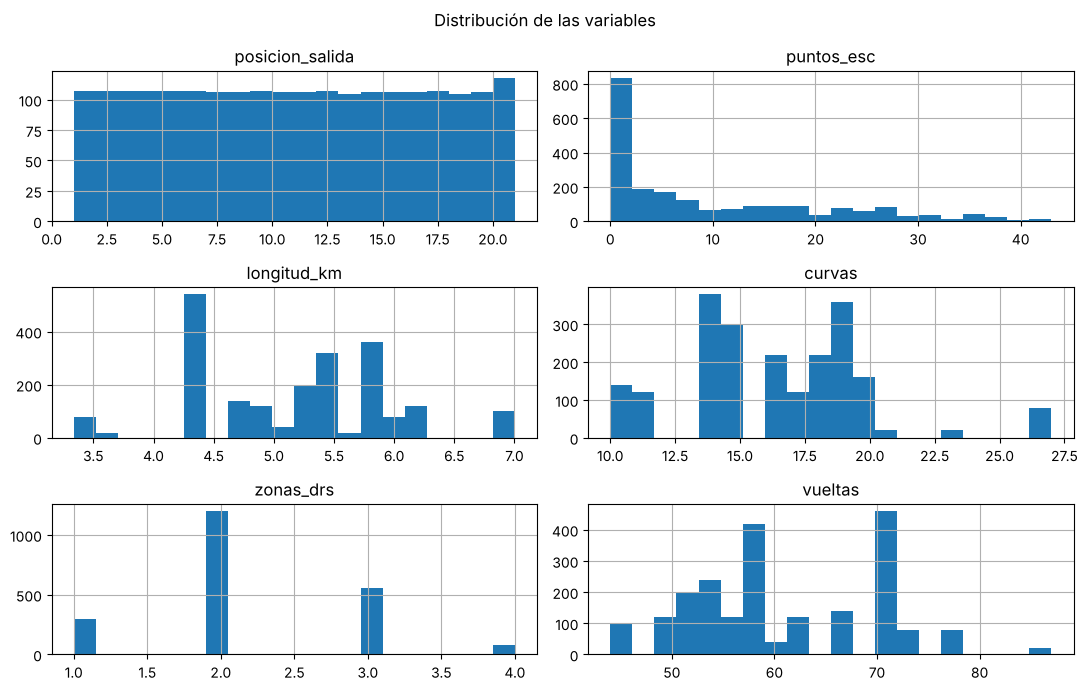

In [10]:
data[numericas + circuito_vars].hist(bins=20, figsize=(11, 7))
plt.suptitle('Distribución de las variables')
plt.tight_layout()
plt.show()

        Frecuencia      %
top_10                   
0             1069  49.98
1             1070  50.02


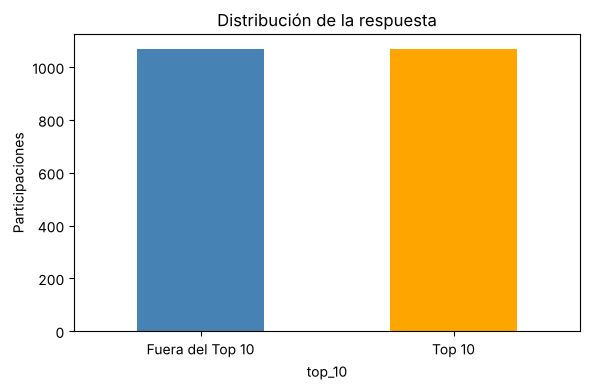

In [11]:
frecuencia = data['top_10'].value_counts().sort_index()
tabla = pd.DataFrame({'Frecuencia': frecuencia, '%': 100 * frecuencia / len(data)})
print(tabla.round(2))
frecuencia.plot.bar(figsize=(6, 4), color=['steelblue', 'orange'])
plt.xticks([0, 1], ['Fuera del Top 10', 'Top 10'], rotation=0)
plt.ylabel('Participaciones')
plt.title('Distribución de la respuesta')
plt.tight_layout()
plt.show()

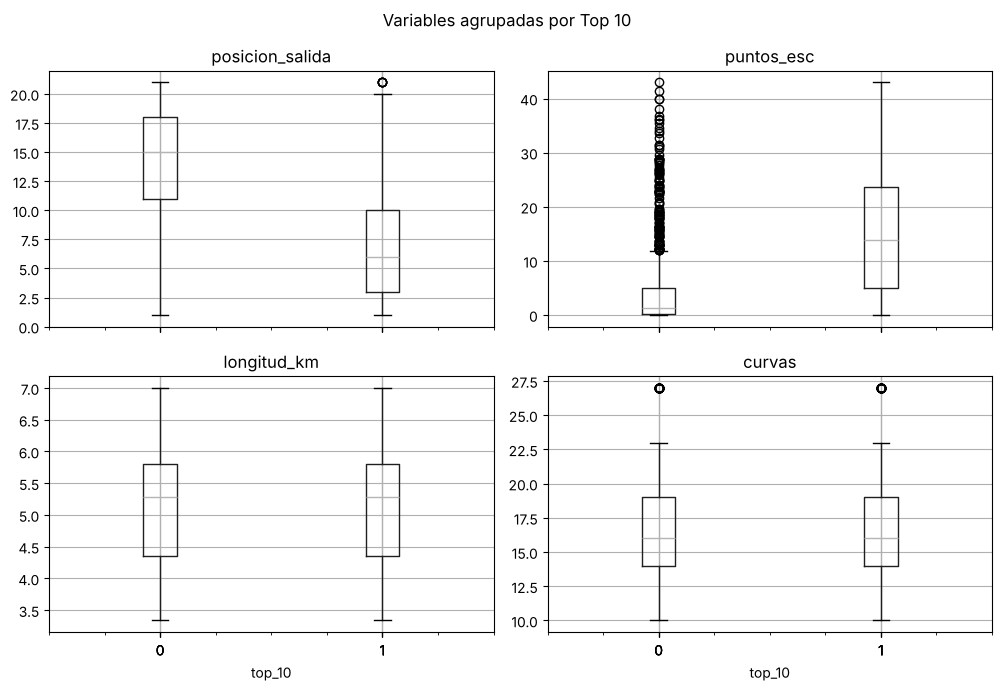

Mediana de salida por grupo:
top_10
0    15.0
1     6.0
Name: posicion_salida, dtype: float64
Mediana de puntos_esc por grupo:
top_10
0     1.333333
1    13.812500
Name: puntos_esc, dtype: float64


In [12]:
data.boxplot(column=['posicion_salida', 'puntos_esc', 'longitud_km', 'curvas'],
             by='top_10', figsize=(10, 7), sharey=False)
plt.suptitle('Variables agrupadas por Top 10')
plt.tight_layout()
plt.show()

print('Mediana de salida por grupo:')
print(data.groupby('top_10')['posicion_salida'].median())
print('Mediana de puntos_esc por grupo:')
print(data.groupby('top_10')['puntos_esc'].median())

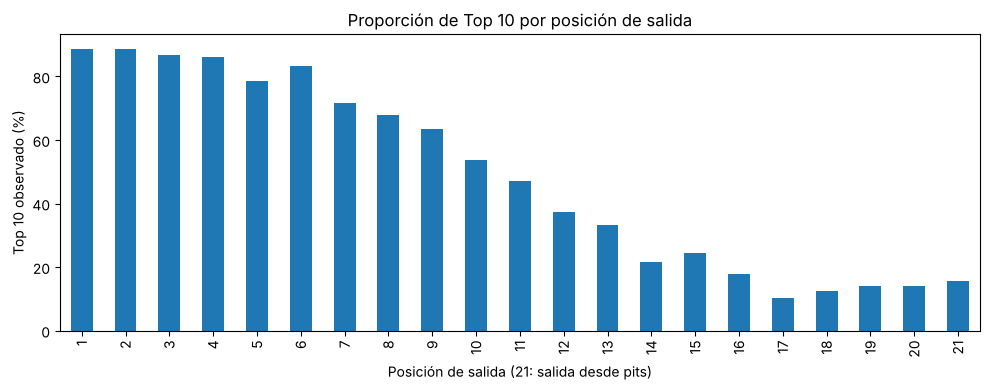

top_10              0     1
posicion_salida            
1                11.2  88.8
2                11.2  88.8
3                13.1  86.9
4                14.0  86.0
5                21.5  78.5
6                16.8  83.2
7                28.3  71.7
8                32.1  67.9
9                36.4  63.6
10               46.2  53.8
11               52.8  47.2
12               62.6  37.4
13               66.7  33.3
14               78.3  21.7
15               75.5  24.5
16               82.1  17.9
17               89.7  10.3
18               87.6  12.4
19               85.8  14.2
20               86.0  14.0
21               84.4  15.6


In [13]:
tabla_salida = pd.crosstab(data['posicion_salida'], data['top_10'], normalize='index') * 100
tabla_salida[1].plot.bar(figsize=(10, 4))
plt.ylabel('Top 10 observado (%)')
plt.xlabel('Posición de salida (21: salida desde pits)')
plt.title('Proporción de Top 10 por posición de salida')
plt.tight_layout()
plt.show()
print(tabla_salida.round(1))

In [14]:
top10_por_carrera = data.groupby(['anio', 'ronda'])['top_10'].sum()
top10_por_carrera.value_counts()

top_10
10    107
Name: count, dtype: int64

### Interpretación del análisis exploratorio

Hay 1,070 participaciones en el Top 10 y 1,069 fuera, así que las clases están balanceadas. Quienes terminan en el Top 10 salen en la mediana desde el 6° lugar y quienes quedan fuera desde el 15°; de los que salen 1° o 2°, el 88.8 % termina en el Top 10, y de los que salen desde pits solo el 15.6 %. La mediana de `puntos_esc` es 13.8 en el Top 10 y 1.3 fuera, por lo que el rendimiento previo de la escudería también se asocia con el resultado.

Las 107 carreras tienen exactamente 10 pilotos en el Top 10. Como las características del circuito son iguales para los 20 pilotos de una carrera, no pueden distinguir quién entra y quién no. Los valores extremos de longitud y vueltas, como Spa o Sakhir exterior, son trazados reales y no se eliminan.

## 5. Transformaciones y pipeline

Se usan `ColumnTransformer`, `StandardScaler` y `OneHotEncoder` como en C2 (Scikit-learn developers, s. f.-e). Las numéricas se escalan con $z=(x-\bar{x})/s$. Tanto el escalamiento como la codificación se ajustan dentro del pipeline y de cada fold, así que no se aprenden usando datos de validación ni la temporada de prueba. Si en 2024 aparece un piloto que no estaba en 2020–2023, su bloque del OneHot queda en ceros. No se aplica imputación porque no hay faltantes.

Se reserva **2024** para la prueba final y se ajusta la búsqueda solamente con **2020–2023**. Es la separación entrenamiento/prueba de clase, adaptada al orden temporal del proyecto.

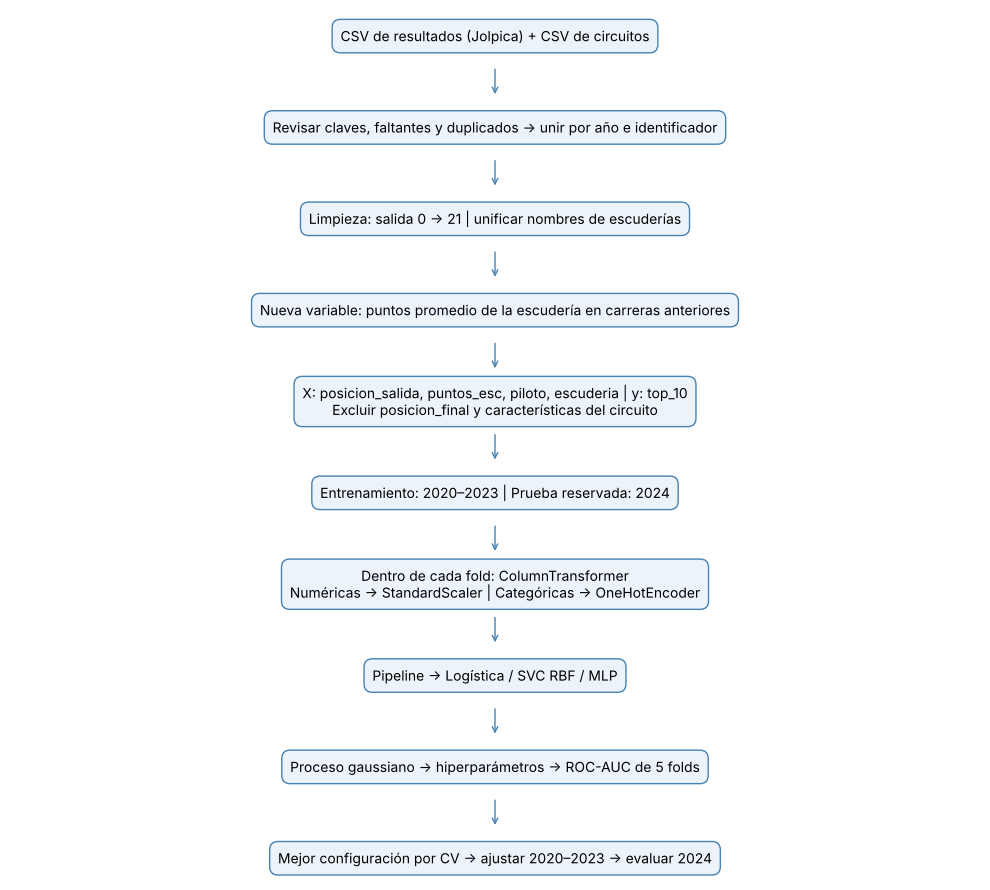

In [15]:
# Diagrama del pipeline
fig, ax = plt.subplots(figsize=(10, 9))
ax.axis('off')
pasos = [
    'CSV de resultados (Jolpica) + CSV de circuitos',
    'Revisar claves, faltantes y duplicados → unir por año e identificador',
    'Limpieza: salida 0 → 21 | unificar nombres de escuderías',
    'Nueva variable: puntos promedio de la escudería en carreras anteriores',
    'X: posicion_salida, puntos_esc, piloto, escuderia | y: top_10\nExcluir posicion_final y características del circuito',
    'Entrenamiento: 2020–2023 | Prueba reservada: 2024',
    'Dentro de cada fold: ColumnTransformer\nNuméricas → StandardScaler | Categóricas → OneHotEncoder',
    'Pipeline → Logística / SVC RBF / MLP',
    'Proceso gaussiano → hiperparámetros → ROC-AUC de 5 folds',
    'Mejor configuración por CV → ajustar 2020–2023 → evaluar 2024'
]
for i, texto in enumerate(pasos):
    y_pos = 0.97 - i * 0.105
    ax.text(0.5, y_pos, texto, ha='center', va='center', fontsize=10,
            bbox=dict(boxstyle='round,pad=0.6', fc='#edf3fa', ec='steelblue'))
    if i < len(pasos) - 1:
        ax.annotate('', xy=(0.5, y_pos - 0.07), xytext=(0.5, y_pos - 0.035),
                    arrowprops=dict(arrowstyle='->', color='steelblue'))
plt.tight_layout()
plt.savefig('resultados/pipeline.png', dpi=150, bbox_inches='tight')
plt.show()

In [16]:
X = data[numericas + categoricas]
y = data['top_10']

X_train = X.loc[data['anio'] < 2024].copy()
X_test = X.loc[data['anio'] == 2024].copy()
y_train = y.loc[data['anio'] < 2024].copy()
y_test = y.loc[data['anio'] == 2024].copy()

print('Entrenamiento:', X_train.shape)
print('Prueba:', X_test.shape)
print('Clases de entrenamiento:', y_train.value_counts().to_dict())
print('Clases de prueba:', y_test.value_counts().to_dict())

kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def preprocesamiento():
    return ColumnTransformer([
        ('num', StandardScaler(), numericas),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categoricas)
    ])

Entrenamiento: (1660, 4)
Prueba: (479, 4)
Clases de entrenamiento: {0: 830, 1: 830}
Clases de prueba: {1: 240, 0: 239}


### Alcance de la validación

Se utilizan cinco folds estratificados, como la evaluación de cinco folds del ejemplo bayesiano, con la estratificación que aparece en C2 y métodos de búsqueda. Todos los modelos usan exactamente la misma partición. Se reportan **media y desviación estándar muestral**, no error estándar.

La validación mezcla temporadas de 2020–2023 y puede poner pilotos de la misma carrera en folds diferentes. Además, se eligen hiperparámetros sobre esos folds. Por eso su mejor media puede ser optimista y no es una evaluación independiente ni una simulación de predicción futura. La prueba reservada de 2024 aporta una comprobación temporal adicional; no se consulta para elegir hiperparámetros. No se afirma validación anidada ni independencia de los folds.

### 5.1. ¿Aportan las características del circuito?

Antes de buscar hiperparámetros comparamos la regresión logística con valores predeterminados, con y sin las variables del circuito, usando los mismos cinco folds de 2020–2023. Esta decisión no consulta 2024.

In [17]:
X_circ = data.loc[data['anio'] < 2024, numericas + categoricas + circuito_vars]

con_circuito = Pipeline([
    ('preprocesamiento', ColumnTransformer([
        ('num', StandardScaler(), numericas + circuito_vars),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categoricas)
    ])),
    ('lr', LogisticRegression(max_iter=1000))
])
sin_circuito = Pipeline([
    ('preprocesamiento', preprocesamiento()),
    ('lr', LogisticRegression(max_iter=1000))
])
solo_circuito = Pipeline([
    ('escala', StandardScaler()),
    ('lr', LogisticRegression(max_iter=1000))
])

print('Con circuito:', cross_val_score(con_circuito, X_circ, y_train, cv=kf, scoring='roc_auc').mean())
print('Sin circuito:', cross_val_score(sin_circuito, X_train, y_train, cv=kf, scoring='roc_auc').mean())
print('Solo circuito:', cross_val_score(solo_circuito, X_circ[circuito_vars], y_train, cv=kf, scoring='roc_auc').mean())

Con circuito: 0.8458702278995499


Sin circuito: 0.8487988096966177
Solo circuito: 0.44287269560168385


Agregar las características del circuito bajó el ROC-AUC medio de 0.8488 a 0.8459, y por sí solas obtienen 0.443, es decir, no ordenan mejor que el azar. Por eso las dejamos fuera de los modelos, como esperábamos en 3.7.

## 6. Modelos propuestos

Todos usan las mismas variables (`posicion_salida`, `puntos_esc`, `piloto` y `escuderia`) y las mismas transformaciones.

| Modelo | Hiperparámetros de búsqueda | Valores fijos |
|:--|:--|:--|
| Regresión logística L2 | `C` entre 0.1 y 10 | `max_iter=1000` |
| SVC RBF | `C` entre 0.1 y 10; `gamma` entre 0.001 y 1 | `kernel='rbf'` |
| MLP | Neuronas entre 5 y 30; `alpha` entre 0.0001 y 0.1 | Una capa oculta, ReLU, Adam, `max_iter=1000` |

Son rangos acotados de exploración, no garantía de óptimo. Para SVC, ROC-AUC utiliza `decision_function`, como permite `cross_val_score`; no hace falta activar probabilidades. Para logística y MLP se usan probabilidades. Se conservan umbrales predeterminados al calcular clases.

In [18]:
def modelo_lr(H):
    return Pipeline([
        ('preprocesamiento', preprocesamiento()),
        ('lr', LogisticRegression(C=H[0], max_iter=1000))
    ])

def modelo_svc(H):
    return Pipeline([
        ('preprocesamiento', preprocesamiento()),
        ('svc', SVC(C=H[0], gamma=H[1], kernel='rbf'))
    ])

def modelo_mlp(H):
    return Pipeline([
        ('preprocesamiento', preprocesamiento()),
        ('mlp', MLPClassifier(hidden_layer_sizes=(int(H[0]),), alpha=H[1],
                              max_iter=1000, random_state=42))
    ])

def objetivo_lr(H):
    score = cross_val_score(modelo_lr(H), X_train, y_train, cv=kf, scoring='roc_auc')
    return np.mean(score)

def objetivo_svc(H):
    score = cross_val_score(modelo_svc(H), X_train, y_train, cv=kf, scoring='roc_auc')
    return np.mean(score)

def objetivo_mlp(H):
    score = cross_val_score(modelo_mlp(H), X_train, y_train, cv=kf, scoring='roc_auc')
    return np.mean(score)

## 7. Optimización bayesiana

El proceso gaussiano aproxima la función objetivo: recibe configuraciones `H` y su media ROC-AUC. En cada modelo se evalúan 35 configuraciones: cinco iniciales y 30 seleccionadas por la cota superior `media + 2 * desviación`. Las candidatas no se evalúan todas con el clasificador; primero las estima el proceso gaussiano.

El siguiente ciclo reproduce la estructura del ejemplo de clase. Se agrupa en una función para repetir exactamente los mismos pasos en los tres modelos. Para MLP las neuronas se generan como enteros; el GP recibe ese número y `alpha`.

In [19]:
def muestra_lr():
    return [np.random.uniform(0.1, 10)]

def muestra_svc():
    return [np.random.uniform(0.1, 10), np.random.uniform(0.001, 1)]

def muestra_mlp():
    return [np.random.randint(5, 31), np.random.uniform(0.0001, 0.1)]

def optimizacion_bayesiana(objetivo, muestra, nombre):
    np.random.seed(42)
    H_inicial = []
    s_inicial = []

    for i in range(5):
        H = muestra()
        s = objetivo(H)
        H_inicial.append(H)
        s_inicial.append(s)

    kernel = 1 * RBF(length_scale=1)
    gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=10,
                                  normalize_y=True, random_state=42)

    for i in range(30):
        gp.fit(np.array(H_inicial), np.array(s_inicial))
        H_sim = []
        for j in range(100):
            H_sim.append(muestra())

        y_pred, desv = gp.predict(np.array(H_sim), return_std=True)
        y_upper = y_pred + 2 * desv
        indice = np.argmax(y_upper)
        H = H_sim[indice]
        s = objetivo(H)
        H_inicial.append(H)
        s_inicial.append(s)
        print(nombre, 'Iteración:', i + 1, 'ROC-AUC:', round(s, 5))

    indice = np.argmax(s_inicial)
    historial = pd.DataFrame(H_inicial)
    historial['ROC-AUC CV'] = s_inicial
    historial['Mejor acumulado'] = np.maximum.accumulate(s_inicial)
    return H_inicial[indice], historial

### 7.1. Regresión logística regularizada

In [20]:
mejor_H_lr, historial_lr = optimizacion_bayesiana(objetivo_lr, muestra_lr, 'Logística')
print('Mejor C:', mejor_H_lr[0])
historial_lr.tail()

Logística Iteración: 1 ROC-AUC: 0.8505
Logística Iteración: 2 ROC-AUC: 0.84952


Logística Iteración: 3 ROC-AUC: 0.85032
Logística Iteración: 4 ROC-AUC: 0.84901


Logística Iteración: 5 ROC-AUC: 0.84756
Logística Iteración: 6 ROC-AUC: 0.84789


Logística Iteración: 7 ROC-AUC: 0.84731
Logística Iteración: 8 ROC-AUC: 0.84733


Logística Iteración: 9 ROC-AUC: 0.85056


Logística Iteración: 10 ROC-AUC: 0.84993


... (11 outputs left out)

Logística Iteración: 28 ROC-AUC: 0.84932


Logística Iteración: 29 ROC-AUC: 0.84926


Logística Iteración: 30 ROC-AUC: 0.84997
Mejor C: 0.1458570277455683


,0,ROC-AUC CV,Mejor acumulado
30,0.289249,0.849931,0.850562
31,0.245465,0.850076,0.850562
32,0.715812,0.849321,0.850562
33,0.783175,0.849263,0.850562
34,0.349415,0.849975,0.850562


#### Interpretación

La mejor configuración observada de la logística usa **C = 0.146** y obtuvo un ROC-AUC medio de **0.8506**. Un C pequeño significa bastante regularización, lo cual tiene sentido porque hay muchas columnas de pilotos con pocas carreras cada una.

### 7.2. Máquina de vectores de soporte RBF

In [21]:
mejor_H_svc, historial_svc = optimizacion_bayesiana(objetivo_svc, muestra_svc, 'SVC')
print('Mejor C y gamma:', mejor_H_svc)
historial_svc.tail()

SVC Iteración: 1 ROC-AUC: 0.81177


/usr/local/lib/python3.13/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


SVC Iteración: 2 ROC-AUC: 0.80485


/usr/local/lib/python3.13/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


SVC Iteración: 3 ROC-AUC: 0.79841


SVC Iteración: 4 ROC-AUC: 0.82983


... (23 outputs left out)

SVC Iteración: 28 ROC-AUC: 0.82907


SVC Iteración: 29 ROC-AUC: 0.84905


SVC Iteración: 30 ROC-AUC: 0.83499
Mejor C y gamma: [2.706148730528311, 0.0016527373705382553]


,0,1,ROC-AUC CV,Mejor acumulado
30,3.079567,0.184861,0.827039,0.849154
31,7.209863,0.125297,0.828063,0.849154
32,2.649044,0.136526,0.829072,0.849154
33,2.787166,0.004699,0.849053,0.849154
34,0.238744,0.567292,0.834994,0.849154


#### Interpretación

La mejor configuración observada del SVC usa **C = 2.71 y gamma = 0.0017** y obtuvo **0.8492**. Un gamma tan pequeño hace que la frontera sea casi lineal, por eso queda muy cerca de la logística.

### 7.3. Multi-layer perceptron

In [22]:
mejor_H_mlp, historial_mlp = optimizacion_bayesiana(objetivo_mlp, muestra_mlp, 'MLP')
print('Mejores neuronas y alpha:', mejor_H_mlp)
historial_mlp.tail()

MLP Iteración: 1 ROC-AUC: 0.84336


MLP Iteración: 2 ROC-AUC: 0.84306


MLP Iteración: 3 ROC-AUC: 0.84553


MLP Iteración: 4 ROC-AUC: 0.84657


MLP Iteración: 5 ROC-AUC: 0.84662


MLP Iteración: 6 ROC-AUC: 0.84674


... (21 outputs left out)

MLP Iteración: 28 ROC-AUC: 0.84622


MLP Iteración: 29 ROC-AUC: 0.84681


MLP Iteración: 30 ROC-AUC: 0.84852
Mejores neuronas y alpha: [11, 0.09288791527271975]


,0,1,ROC-AUC CV,Mejor acumulado
30,5,0.097705,0.848313,0.848450
31,5,0.012770,0.847877,0.848450
32,7,0.014085,0.846222,0.848450
33,9,0.098126,0.846810,0.848450
34,11,0.092888,0.848516,0.848516


#### Interpretación

La mejor configuración observada de la MLP usa **una capa de 11 neuronas y alpha = 0.093** y obtuvo **0.8485**. Todas las configuraciones evaluadas quedaron entre 0.838 y 0.849, así que el número de neuronas cambió poco el resultado.

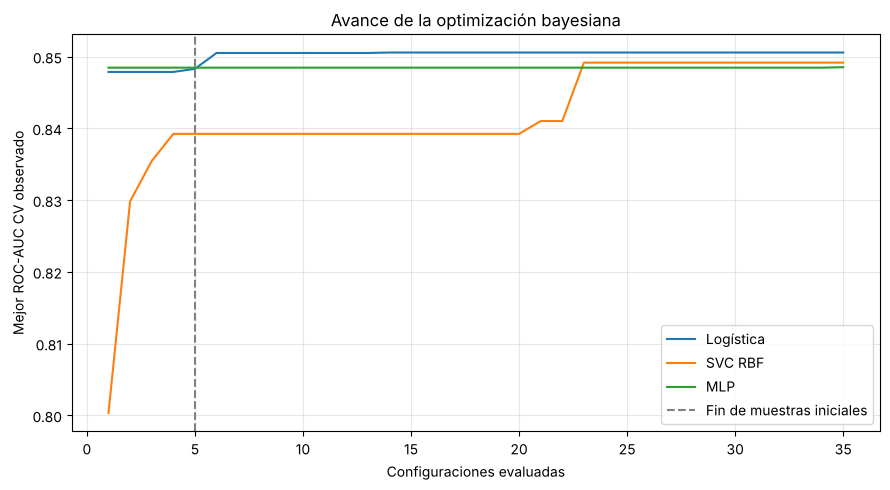

In [23]:
plt.figure(figsize=(9, 5))
for nombre, historial in [('Logística', historial_lr), ('SVC RBF', historial_svc), ('MLP', historial_mlp)]:
    plt.plot(np.arange(1, len(historial) + 1), historial['Mejor acumulado'], label=nombre)
plt.axvline(5, color='gray', linestyle='--', label='Fin de muestras iniciales')
plt.xlabel('Configuraciones evaluadas')
plt.ylabel('Mejor ROC-AUC CV observado')
plt.title('Avance de la optimización bayesiana')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('resultados/busqueda.png', dpi=150)
plt.show()

historial_lr.to_csv('resultados/busqueda_logistica.csv', index=False)
historial_svc.to_csv('resultados/busqueda_svc.csv', index=False)
historial_mlp.to_csv('resultados/busqueda_mlp.csv', index=False)

### Interpretación de la búsqueda

Cada búsqueda evaluó 35 configuraciones. La curva muestra el mejor resultado acumulado, por eso nunca baja.

- **Logística:** las cinco configuraciones iniciales ya llegaban a 0.8483 y la búsqueda subió a 0.8506.
- **SVC RBF:** es donde más ayudó la búsqueda, pasó de 0.8392 a 0.8492; algunas combinaciones de C y gamma bajaban hasta 0.798.
- **MLP:** el mejor valor inicial (0.8485) prácticamente no se superó.

Las advertencias del proceso gaussiano en el SVC indican que algunos ajustes tocaron el límite inferior de `length_scale`. No detienen la búsqueda, pero recuerdan que no garantiza encontrar el óptimo global.

## 8. Comparación en validación cruzada

Se evalúa la mejor configuración de cada búsqueda con los mismos cinco folds y se compara con una configuración inicial fija. También se agrega una **referencia**: una regresión logística que solo usa la posición de salida. Si un modelo no supera esa referencia, no aporta nada más que ordenar a los pilotos por la parrilla.

In [24]:
modelos_base = {
    'Logística': modelo_lr([1]),
    'SVC RBF': modelo_svc([1, 0.1]),
    'MLP': modelo_mlp([10, 0.0001])
}
modelos = {
    'Logística': modelo_lr(mejor_H_lr),
    'SVC RBF': modelo_svc(mejor_H_svc),
    'MLP': modelo_mlp(mejor_H_mlp)
}

filas = []
folds = pd.DataFrame()
for nombre in modelos:
    base = cross_val_score(modelos_base[nombre], X_train, y_train, cv=kf, scoring='roc_auc')
    scores = cross_val_score(modelos[nombre], X_train, y_train, cv=kf, scoring='roc_auc')
    folds[nombre] = scores
    filas.append([nombre, base.mean(), scores.mean(), scores.std(ddof=1)])

comparacion_cv = pd.DataFrame(filas, columns=['Modelo', 'AUC base', 'AUC CV media', 'AUC CV desviación'])
ganador_cv = comparacion_cv.loc[comparacion_cv['AUC CV media'].idxmax(), 'Modelo']
print('Modelo seleccionado por CV:', ganador_cv)
print('AUC por fold:')
print(folds.round(4))
comparacion_cv.round(4)

Modelo seleccionado por CV: Logística
AUC por fold:
   Logística  SVC RBF     MLP
0     0.8337   0.8301  0.8387
1     0.8658   0.8637  0.8687
2     0.8644   0.8643  0.8550
3     0.8467   0.8437  0.8557
4     0.8422   0.8440  0.8244


,Modelo,AUC base,AUC CV media,AUC CV desviación
0,Logística,0.8488,0.8506,0.0141
1,SVC RBF,0.8353,0.8492,0.0147
2,MLP,0.8446,0.8485,0.0172


In [25]:
solo_salida = cross_val_score(LogisticRegression(), X_train[['posicion_salida']], y_train, cv=kf, scoring='roc_auc')
print('Referencia solo salida, media:', solo_salida.mean())
print('Referencia solo salida, desviación:', solo_salida.std(ddof=1))

Referencia solo salida, media: 0.8129191464653797
Referencia solo salida, desviación: 0.01581664166903727


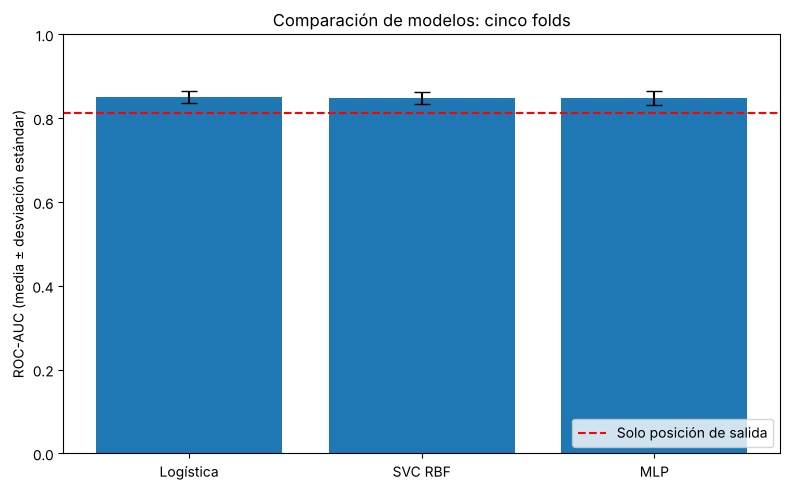

In [26]:
plt.figure(figsize=(8, 5))
plt.bar(comparacion_cv['Modelo'], comparacion_cv['AUC CV media'],
        yerr=comparacion_cv['AUC CV desviación'], capsize=6)
plt.axhline(solo_salida.mean(), color='red', linestyle='--', label='Solo posición de salida')
plt.ylabel('ROC-AUC (media ± desviación estándar)')
plt.ylim(0, 1)
plt.title('Comparación de modelos: cinco folds')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('resultados/comparacion_cv.png', dpi=150)
plt.show()

comparacion_cv.to_csv('resultados/comparacion_cv.csv', index=False)
folds.to_csv('resultados/auc_por_fold.csv', index=False)

### Interpretación de la validación cruzada

Los tres modelos quedaron prácticamente empatados: logística **0.8506 ± 0.0141**, SVC RBF **0.8492 ± 0.0147** y MLP **0.8485 ± 0.0172**. La diferencia entre el primero y el último es 0.002, mucho menor que la desviación entre folds, así que no podemos decir que uno sea mejor que otro. Seleccionamos la **regresión logística** antes de revisar 2024 por tener la media más alta y ser el modelo más simple.

Los tres superan a la referencia que solo usa la posición de salida (**0.8129 ± 0.0158**) por unos 0.036 puntos de AUC. Frente a la configuración inicial fija, la búsqueda mejoró al SVC en 0.014 y a la logística y la MLP en menos de 0.004.

## 9. Evaluación final en 2024

Cada modelo se ajusta con todas las filas de 2020–2023 usando sus hiperparámetros elegidos por CV. Después se evalúa una vez sobre 2024 para comparar generalización temporal, sin cambiar configuraciones a partir de esos resultados. El modelo recomendado ya quedó elegido por CV.

Logística
                  precision    recall  f1-score   support

Fuera del Top 10       0.80      0.83      0.81       239
          Top 10       0.82      0.80      0.81       240

        accuracy                           0.81       479
       macro avg       0.81      0.81      0.81       479
    weighted avg       0.81      0.81      0.81       479

SVC RBF


                  precision    recall  f1-score   support

Fuera del Top 10       0.81      0.85      0.83       239
          Top 10       0.85      0.80      0.82       240

        accuracy                           0.83       479
       macro avg       0.83      0.83      0.83       479
    weighted avg       0.83      0.83      0.83       479



MLP
                  precision    recall  f1-score   support

Fuera del Top 10       0.82      0.82      0.82       239
          Top 10       0.82      0.82      0.82       240

        accuracy                           0.82       479
       macro avg       0.82      0.82      0.82       479
    weighted avg       0.82      0.82      0.82       479



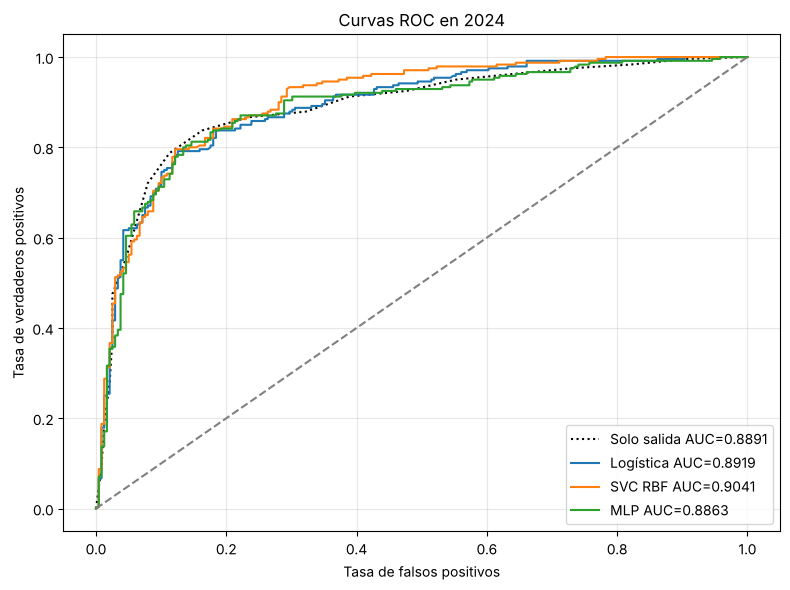

,Modelo,AUC 2024,Accuracy,Precision,Recall
0,Solo posición de salida,0.8891,0.8372,0.8375,0.8375
1,Logística,0.8919,0.8121,0.8233,0.7958
2,SVC RBF,0.9041,0.8267,0.8458,0.8000
3,MLP,0.8863,0.8246,0.8250,0.8250


In [27]:
filas_test = []
predicciones = data.loc[data['anio'] == 2024, ['anio', 'ronda', 'piloto', 'top_10']].copy()
plt.figure(figsize=(8, 6))

ref = LogisticRegression()
ref.fit(X_train[['posicion_salida']], y_train)
pred_ref = ref.predict(X_test[['posicion_salida']])
score_ref = ref.predict_proba(X_test[['posicion_salida']])[:, 1]
auc_ref = roc_auc_score(y_test, score_ref)
filas_test.append(['Solo posición de salida', auc_ref, accuracy_score(y_test, pred_ref),
                   precision_score(y_test, pred_ref), recall_score(y_test, pred_ref)])
fpr, tpr, thresholds = roc_curve(y_test, score_ref)
plt.plot(fpr, tpr, ':', color='black', label='Solo salida AUC=' + str(round(auc_ref, 4)))

for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    pred = modelo.predict(X_test)
    if nombre == 'SVC RBF':
        puntuacion = modelo.decision_function(X_test)
    else:
        puntuacion = modelo.predict_proba(X_test)[:, 1]

    auc = roc_auc_score(y_test, puntuacion)
    filas_test.append([nombre, auc, accuracy_score(y_test, pred),
                       precision_score(y_test, pred, zero_division=0),
                       recall_score(y_test, pred, zero_division=0)])
    print(nombre)
    print(classification_report(y_test, pred, target_names=['Fuera del Top 10', 'Top 10'], zero_division=0))
    predicciones[nombre + '_pred'] = pred
    predicciones[nombre + '_score'] = puntuacion

    fpr, tpr, thresholds = roc_curve(y_test, puntuacion)
    plt.plot(fpr, tpr, label=nombre + ' AUC=' + str(round(auc, 4)))

plt.plot([0, 1], [0, 1], '--', color='gray')
plt.xlabel('Tasa de falsos positivos')
plt.ylabel('Tasa de verdaderos positivos')
plt.title('Curvas ROC en 2024')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('resultados/roc_2024.png', dpi=150)
plt.show()

comparacion_test = pd.DataFrame(filas_test, columns=['Modelo', 'AUC 2024', 'Accuracy', 'Precision', 'Recall'])
comparacion_test.to_csv('resultados/evaluacion_2024.csv', index=False)
predicciones.to_csv('resultados/predicciones_2024.csv', index=False)
comparacion_test.round(4)

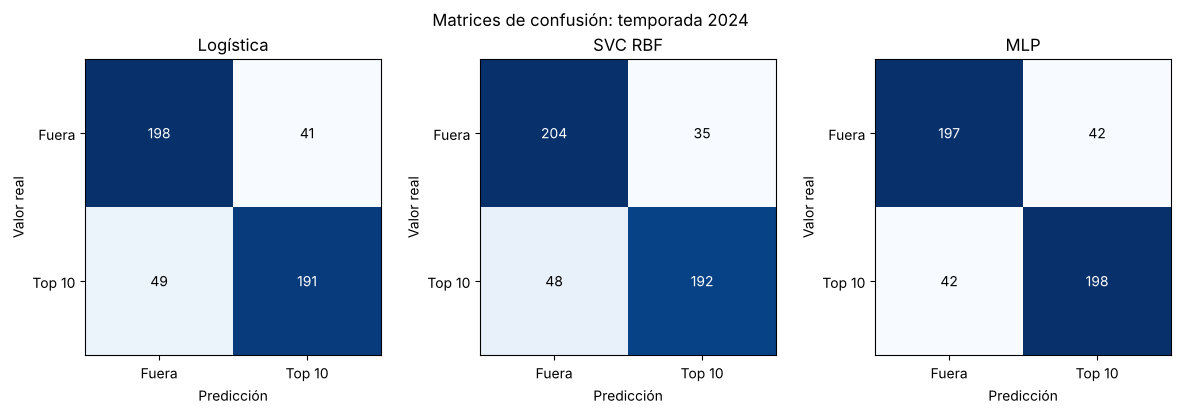

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
matrices = {}
for ax, (nombre, modelo) in zip(axes, modelos.items()):
    mat = confusion_matrix(y_test, modelo.predict(X_test), labels=[0, 1])
    matrices[nombre] = mat
    ax.imshow(mat, cmap='Blues')
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(mat[i, j]), ha='center', va='center',
                    color='white' if mat[i, j] > mat.max() / 2 else 'black')
    ax.set(xticks=[0, 1], yticks=[0, 1], xlabel='Predicción', ylabel='Valor real', title=nombre)
    ax.set_xticklabels(['Fuera', 'Top 10'])
    ax.set_yticklabels(['Fuera', 'Top 10'])
plt.suptitle('Matrices de confusión: temporada 2024')
plt.tight_layout()
plt.savefig('resultados/matrices_confusion.png', dpi=150)
plt.show()

### Interpretación de los resultados de prueba

- **Logística (seleccionada por CV):** AUC **0.8919** y accuracy **81.2 %**. Identificó 191 de los 240 Top 10 y marcó como Top 10 a 41 de los 239 que quedaron fuera.
- **SVC RBF:** AUC **0.9041** y accuracy **82.7 %**, con 192 Top 10 identificados y 35 falsos positivos.
- **MLP:** AUC **0.8863** y accuracy **82.5 %**, con 198 Top 10 identificados y 42 falsos positivos.
- **Solo posición de salida:** AUC **0.8891** y accuracy **83.7 %**.

En 2024 la ventaja que vimos en la validación cruzada casi desaparece. La logística supera a la referencia por solo 0.003 de AUC, la MLP queda por debajo y el SVC es el único con una mejora visible (0.015). Con el umbral predeterminado, ninguno supera el accuracy de la referencia. Una posible explicación es que las columnas de piloto y escudería aprenden el historial de 2020–2023, que no se repite igual en 2024.

Mantenemos la logística como modelo seleccionado aunque el SVC tenga mejor AUC en 2024, porque cambiar la elección con base en la prueba la convertiría en parte del ajuste. El AUC mide qué tan bien se ordenan las dos clases y no es el porcentaje de pilotos acertados.

### 9.1. ¿Qué variables se asocian más con el Top 10?

Usamos los coeficientes de la regresión logística ajustada con 2020–2023. Como las numéricas están estandarizadas, su coeficiente indica cuánto cambia el log-odds de terminar en el Top 10 cuando la variable sube una desviación estándar. En piloto y escudería, cada coeficiente compara contra el promedio de las demás categorías.

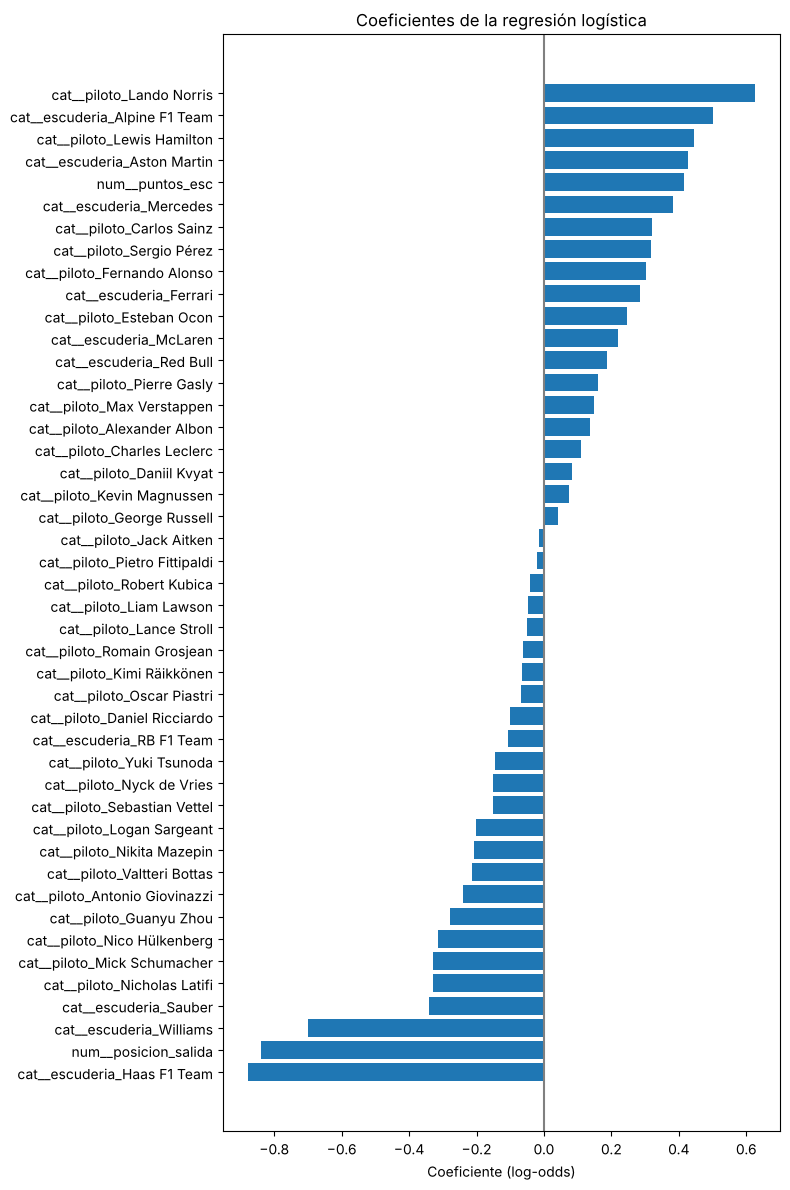

num__posicion_salida   -0.838402
num__puntos_esc         0.416483
dtype: float64


In [29]:
lr_final = modelos['Logística']
nombres = lr_final.named_steps['preprocesamiento'].get_feature_names_out()
coef = lr_final.named_steps['lr'].coef_[0]
coeficientes = pd.Series(coef, index=nombres).sort_values()

plt.figure(figsize=(8, 12))
plt.barh(coeficientes.index, coeficientes.values)
plt.axvline(0, color='gray')
plt.xlabel('Coeficiente (log-odds)')
plt.title('Coeficientes de la regresión logística')
plt.tight_layout()
plt.savefig('resultados/coeficientes_logistica.png', dpi=150)
plt.show()

print(coeficientes[['num__posicion_salida', 'num__puntos_esc']])

La posición de salida y `puntos_esc` están entre las variables que más pesan. Salir una desviación estándar más atrás (unas 6 posiciones) baja el log-odds en 0.84, y una desviación más de `puntos_esc` (unos 11 puntos por carrera) lo sube en 0.42.

Entre las categorías destacan Haas (−0.88) y Williams (−0.70) en negativo y Lando Norris (0.63) en positivo. Como la salida y los puntos ya están en el modelo, estos coeficientes indican qué equipos y pilotos terminan mejor o peor de lo que sugieren su salida y sus puntos. Se asocian con el resultado; no demuestran que lo causen.

### Limitaciones

- Las características del circuito son una compilación que no se verificó contra una fuente oficial; de todas formas no forman parte del modelo final.
- `puntos_esc` es aproximado: no incluye sprints ni vuelta rápida, y vale 0 en la primera carrera de cada temporada.
- Los pilotos de una misma carrera están relacionados y pueden caer en folds distintos. Además, las variables y los hiperparámetros se eligieron con esos mismos folds, así que la media de la CV puede ser optimista.
- La prueba es una sola temporada (479 participaciones); diferencias de 0.01 de AUC entre modelos podrían cambiar en otra temporada.
- Piloto y escudería aprenden el historial de 2020–2023. Los pilotos nuevos de 2024 quedan en ceros en el OneHot.
- No se incluyen clima, averías, incidentes ni estrategia, que ocurren después de la salida.

## 10. Conclusión

Comparamos regresión logística, SVC con kernel RBF y una MLP para predecir si un piloto termina en el Top 10 usando solo información previa a la carrera.

Unimos las 2,139 participaciones con las características de los circuitos sin faltantes ni duplicados y confirmamos los resultados contra la API de Jolpica (objetivo 1). Tratamos la posición de salida como numérica, unificamos los nombres de las escuderías y construimos `puntos_esc` con las carreras anteriores de cada temporada; el escalamiento y el OneHot se ajustaron dentro del pipeline (objetivo 2). Las características del circuito no aportaron y quedaron fuera.

Con la optimización por procesos gaussianos, los tres modelos quedaron empatados en validación cruzada, alrededor de 0.85 de ROC-AUC, y los tres superaron por unos 0.036 a la referencia que solo usa la posición de salida (objetivos 3 y 4). Seleccionamos la logística por tener la media más alta y ser la más simple.

En 2024 la logística obtuvo AUC 0.892 contra 0.889 de la referencia, así que la mejora casi desaparece en una temporada que el modelo no vio (objetivo 5). Las variables más asociadas con el Top 10 son la posición de salida y los puntos previos de la escudería.

Respondiendo la pregunta de investigación: con estos datos ningún modelo es claramente mejor que los otros, y la posición de salida por sí sola explica casi todo lo que se puede predecir antes de la carrera. El rendimiento de la escudería en la temporada ayuda en la validación cruzada, pero en una temporada nueva la ganancia es pequeña.

## 11. Referencias

James, G., Witten, D., Hastie, T., Tibshirani, R., & Taylor, J. (2023). *An introduction to statistical learning: With applications in Python*. Springer. https://www.statlearning.com/

Jolpica. (s. f.). *Jolpica F1 API: Resultados de Fórmula 1, continuación de Ergast* [API]. Recuperado el 2 de noviembre de 2026, de https://api.jolpi.ca/ergast/f1/

Scikit-learn developers. (s. f.-a). *Gaussian processes*. https://scikit-learn.org/stable/modules/gaussian_process.html

Scikit-learn developers. (s. f.-b). *Linear models: Logistic regression*. https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression

Scikit-learn developers. (s. f.-c). *Metrics and scoring: Quantifying the quality of predictions*. https://scikit-learn.org/stable/modules/model_evaluation.html

Scikit-learn developers. (s. f.-d). *Neural network models (supervised)*. https://scikit-learn.org/stable/modules/neural_networks_supervised.html

Scikit-learn developers. (s. f.-e). *Pipelines and composite estimators*. https://scikit-learn.org/stable/modules/compose.html

Scikit-learn developers. (s. f.-f). *Support vector machines*. https://scikit-learn.org/stable/modules/svm.html

ITESO. (2026). *Lab - C1*, *Lab - C2*, *Lab - C3*, *regresionlogistica*, *04_Ingenieria_inversa*, *ModeloMLP*, *Laboratorio de métodos de búsqueda* y *Optimización Bayesiana* [Notebooks de Jupyter, material de clase]. Instituto Tecnológico y de Estudios Superiores de Occidente.